# Reference and target samples

Compare two mixtures using **`weight_kFact`** as the event weight:

| Sample | Selection |
|---|---|
| Reference | `Type` is `S` or `EWSBI10` |
| Target | `Type` is `SBI` or `qqZZ` |

The two plots compare `NN_disc_New` and `m4l_fsr`. By default, each combined mixture is normalized to unit area for a shape comparison; component processes retain their relative weighted contributions. Set `DENSITY = False` for the sum of event weights per bin. Negative weights are retained in both modes.

Run all cells on a CPU runtime. Figures are displayed here and saved as PNG/PDF under the project folder in Drive.

## Setup

Colab loads `utils.py` from this repository. That file contains the HDF5 column reader and plot styling; selections, binning, and weighted histograms are below.

In [1]:
%pip -q install mplhep tables

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 834.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.7/93.7 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 46.9 MB/s eta 0:00:00


In [2]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplhep as hep
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    from utils import load_columns, plot_comparison
else:
    drive.mount("/content/drive")
    urlretrieve(
        "https://raw.githubusercontent.com/rafaellopesdesa/offshell_reweighting/main/utils.py",
        "/content/offshell_utils.py",
    )
    from offshell_utils import load_columns, plot_comparison

hep.style.use("ATLAS")

Mounted at /content/drive


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/HZZ_OffShell")
DATA_PATH = PROJECT_DIR / "dataset_wDR_mean_origIndex.h5"
PLOT_DIR = PROJECT_DIR / "plots" / "01_reference_sample"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

DENSITY = True   # False: sum of weight_kFact in each bin.
N_BINS = 50

## Load four columns and select the samples

The input contains a pandas fixed-format group named `dataset`. Reading only these columns keeps memory use smaller than loading the whole 66-column DataFrame. `Type` is stored together with `subType` in an object block, which must be read together once.

Rows with nonfinite values in either plotted variable or the weight are excluded from both plots and counted below. No other event cuts or process-dependent rescaling are applied.

In [4]:
data = load_columns(DATA_PATH, ["Type", "weight_kFact", "NN_disc_New", "m4l_fsr"])
event_type = data["Type"]
weights = np.asarray(data["weight_kFact"], dtype=np.float64)

reference = np.isin(event_type, ["S", "EWSBI10"])
target = np.isin(event_type, ["SBI", "qqZZ"])

finite = (np.isfinite(weights) & np.isfinite(data["NN_disc_New"])
          & np.isfinite(data["m4l_fsr"]))
print(f"Excluded nonfinite rows: reference={np.count_nonzero(reference & ~finite):,}, "
      f"target={np.count_nonzero(target & ~finite):,}")
reference &= finite
target &= finite

summary = []
for name, mask in [("Reference", reference), ("Target", target)]:
    summary.append({"sample": name, "events": int(mask.sum()),
                    "sum_weights": weights[mask].sum(),
                    "negative_weights": int(np.count_nonzero(weights[mask] < 0))})
display(pd.DataFrame(summary).set_index("sample"))

Excluded nonfinite rows: reference=0, target=0


,events,sum_weights,negative_weights
sample,,,
Reference,3110759,91.773434,1333
Target,4317574,2010.603823,488283


## Histogram settings

Both samples use the same 50 bins for each variable. The default edges span all selected finite values, including values of `NN_disc_New` outside `[0, 1]`. You can replace either edge array with `np.linspace(...)` for a chosen range; values outside a custom range are then excluded and unit-area normalization applies within that range.

In [5]:
selected = reference | target
NN_BINS = np.histogram_bin_edges(data["NN_disc_New"][selected], bins=N_BINS)
M4L_BINS = np.histogram_bin_edges(data["m4l_fsr"][selected], bins=N_BINS)

if not reference.any() or not target.any():
    raise ValueError("Both reference and target selections must contain events.")
if DENSITY and (weights[reference].sum() <= 0 or weights[target].sum() <= 0):
    raise ValueError("Unit-area probability shapes require a positive net weight in each sample; use DENSITY=False to inspect weighted yields.")
print("Normalization:", "unit area per mixture" if DENSITY else "sum of event weights per bin")
print("NN_disc_New range:", NN_BINS[[0, -1]])
print("m4l_fsr range:", M4L_BINS[[0, -1]])

Normalization: unit area per mixture
NN_disc_New range: [-0.8499997  1.2310371]
m4l_fsr range: [ 180.00009 1999.9719 ]


## `NN_disc_New`

The histogram sums signed event weights. With `density=True`, NumPy divides by the total in-range weight and by each bin width.

TypeError: Unexpected Text._get_layout format: layout[2]=7.0. The private matplotlib API may have changed.

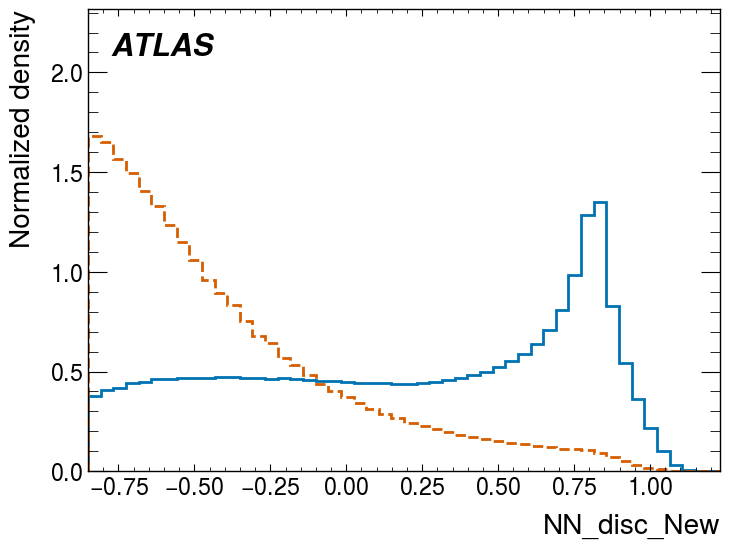

In [6]:
x = data["NN_disc_New"]
h_reference, _ = np.histogram(x[reference], bins=NN_BINS, weights=weights[reference], density=DENSITY)
h_target, _ = np.histogram(x[target], bins=NN_BINS, weights=weights[target], density=DENSITY)

fig, ax = plot_comparison(
    h_reference, h_target, NN_BINS, xlabel="NN_disc_New",
    ylabel="Normalized density" if DENSITY else "Sum of event weights / bin",
)
for extension in ("png", "pdf"):
    fig.savefig(PLOT_DIR / f"NN_disc_New.{extension}", dpi=180, bbox_inches="tight")
plt.show()

## `m4l_fsr`

The mass is plotted in its stored units, taken to be GeV.

In [ ]:
x = data["m4l_fsr"]
h_reference, _ = np.histogram(x[reference], bins=M4L_BINS, weights=weights[reference], density=DENSITY)
h_target, _ = np.histogram(x[target], bins=M4L_BINS, weights=weights[target], density=DENSITY)

fig, ax = plot_comparison(
    h_reference, h_target, M4L_BINS, xlabel=r"$m_{4\ell}^{\mathrm{FSR}}$ [GeV]",
    ylabel=r"Normalized density [GeV$^{-1}$]" if DENSITY else "Sum of event weights / bin",
)
for extension in ("png", "pdf"):
    fig.savefig(PLOT_DIR / f"m4l_fsr.{extension}", dpi=180, bbox_inches="tight")
plt.show()
print(f"Figures saved to {PLOT_DIR}")